# Implement GPT model from scratch to generate text

## Coding the LLM Architecture

In [33]:
GPT_CONFIG_124M = {
    "n_layers": 12,
    "n_heads": 12,
    "emb_dim": 768,
    "vocab_size": 50257,
    "context_length": 1024,
    "drop_rate": 0.1,
    "qkv_bias": False,
}

In [34]:
import torch
import torch.nn as nn


class DummyGPTModel(nn.Module):
    def __int__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.tok_pos = nn.Embedding(cfg["context_lenght"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        # self.trf_blocks = nn.Sequential(
            
        # )
        


In [35]:
import tiktoken

## Normalizing Activation with Layer Normalization

In [36]:
torch.manual_seed(123)
batch = torch.randn(5, 4)
batch

tensor([[ 0.3374, -0.1778, -0.3035, -0.5880],
        [ 1.5810,  1.3010,  1.2753, -0.2010],
        [-0.1606, -0.4015,  0.6957, -1.8061],
        [-1.1589,  0.3255, -0.6315, -2.8400],
        [-0.7849, -1.4096, -0.4076,  0.7953]])

In [37]:
layer = nn.Sequential(nn.Linear(4, 8), nn.ReLU())
out = layer(batch)
out

tensor([[0.0000, 0.0000, 0.4002, 0.2838, 0.0000, 0.0000, 0.5021, 0.0082],
        [0.0000, 0.0000, 0.2819, 1.6122, 0.0946, 0.0000, 0.3349, 0.0000],
        [0.0000, 0.0000, 0.2426, 0.0386, 0.3438, 0.2276, 0.3083, 0.0532],
        [0.0844, 0.0000, 0.3158, 0.0000, 0.9327, 1.2256, 1.5051, 0.4782],
        [0.2165, 1.0807, 0.5417, 0.0000, 0.0000, 0.0000, 0.0000, 0.1431]],
       grad_fn=<ReluBackward0>)

In [38]:
means = out.mean(dim=-1, keepdim=True)
var = out.var(dim=-1, keepdim=True)
means, var

(tensor([[0.1493],
         [0.2905],
         [0.1518],
         [0.5677],
         [0.2478]], grad_fn=<MeanBackward1>),
 tensor([[0.0449],
         [0.3036],
         [0.0206],
         [0.3421],
         [0.1482]], grad_fn=<VarBackward0>))

In [39]:
# apply the normlization
normed = ((out - means) / torch.sqrt(var))
torch.set_printoptions(sci_mode=False) # this will turn off the scitific mode
normed.mean(dim=-1, keepdim=True), normed.var(dim=-1, keepdim=True)

(tensor([[ 0.0000],
         [ 0.0000],
         [ 0.0000],
         [-0.0000],
         [ 0.0000]], grad_fn=<MeanBackward1>),
 tensor([[1.0000],
         [1.0000],
         [1.0000],
         [1.0000],
         [1.0000]], grad_fn=<VarBackward0>))

In [ ]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()   

        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        normed_x = ((x - mean) / torch.sqrt(var + self.eps))
        return self.scale * normed_x + self.shift
    

normed_layer = LayerNorm(batch.shape[-1])
normed = normed_layer(batch)
normed.mean(dim=-1, keepdim=True), normed.var(dim=-1, keepdim=True)

(tensor([[-0.0000],
         [ 0.0000],
         [ 0.0000],
         [ 0.0000],
         [-0.0000]], grad_fn=<MeanBackward1>),
 tensor([[1.3332],
         [1.3333],
         [1.3333],
         [1.3333],
         [1.3333]], grad_fn=<VarBackward0>))

## Implement feedfoward with GeLU Activation Functions


In [41]:
class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) * 
            (x + 0.044715 * torch.pow(x, 3))
        ))


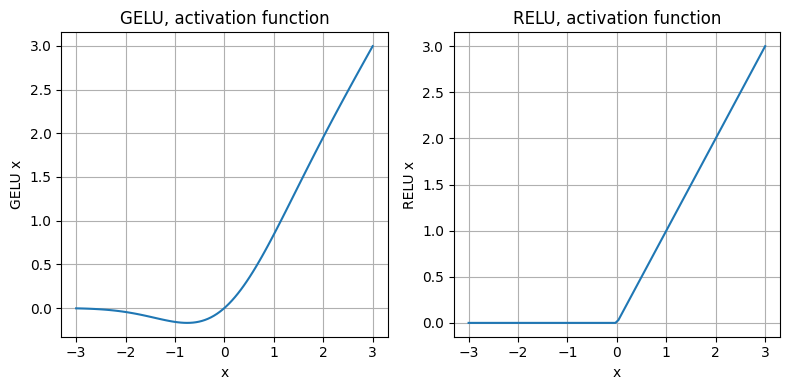

In [42]:
import matplotlib.pyplot as plt

gelu, relu = GELU(), nn.ReLU()

x = torch.linspace(-3, 3, 100)
gelu_y , relu_y = gelu(x), relu(x)

plt.figure(figsize=(8,4))
for i, (y, label) in enumerate(zip([gelu_y, relu_y], ["GELU", "RELU"]), 1):
    plt.subplot(1, 2, i)
    plt.plot(x, y)
    plt.title(f"{label}, activation function")
    plt.xlabel('x')
    plt.ylabel(f'{label} x')
    plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
            GELU(),
            nn.Linear( 4 * cfg["emb_dim"],  cfg["emb_dim"])
        )

    def forward(self, x):
        return self.layers(x)
    
ffn = FeedForward(GPT_CONFIG_124M)

In [44]:
x = torch.rand(2, 3, 768)
ffn(x).shape


torch.Size([2, 3, 768])

In [45]:
ffn.layers

Sequential(
  (0): Linear(in_features=768, out_features=3072, bias=True)
  (1): GELU()
  (2): Linear(in_features=3072, out_features=768, bias=True)
)

In [46]:
ffn.layers[0].weight

Parameter containing:
tensor([[ 0.0148, -0.0353, -0.0022,  ...,  0.0333, -0.0356,  0.0199],
        [-0.0170, -0.0258,  0.0280,  ...,  0.0240,  0.0314,  0.0344],
        [ 0.0082,  0.0230,  0.0001,  ..., -0.0335,  0.0171, -0.0037],
        ...,
        [ 0.0281,  0.0268, -0.0041,  ..., -0.0031, -0.0273, -0.0046],
        [-0.0025, -0.0127, -0.0169,  ..., -0.0045, -0.0046, -0.0345],
        [ 0.0264, -0.0037,  0.0053,  ..., -0.0051, -0.0041,  0.0070]],
       requires_grad=True)

## Adding the shortcut connections

In [47]:
class ExampleDNN(nn.Module):
    def __init__(self, layer_sizes, use_shortcut):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_sizes[0], layer_sizes[1]),  GELU()),
            nn.Sequential(nn.Linear(layer_sizes[1], layer_sizes[2]),  GELU()),
            nn.Sequential(nn.Linear(layer_sizes[2], layer_sizes[3]),  GELU()),
            nn.Sequential(nn.Linear(layer_sizes[3], layer_sizes[4]),  GELU()),
            nn.Sequential(nn.Linear(layer_sizes[4], layer_sizes[5]),  GELU()),
            ])
    
    def forward(self,x):
        for layer in self.layers:
            layer_output = layer(x)
            if self.use_shortcut and x.shape == layer_output.shape:
                x = x + layer_output
            else:
                x = layer_output
        return x 

def print_gradients(model, x):
    output = model(x)
    target = torch.tensor([[0.]])

    loss = nn.MSELoss()
    loss = loss(output, target)

    loss.backward()

    for name, param in model.named_parameters():
        if 'weight' in name:
            print(f' {name} has gradient mean of {param.grad.abs().mean().item() }')



In [48]:
layer_sizes = [3,3, 3,3,3,1]
sample_input = torch.tensor([[1., 0., 1.]])

In [49]:
torch.manual_seed(123)
model_without_shortcut = ExampleDNN(
    layer_sizes, use_shortcut=False
)
print_gradients(model_without_shortcut, sample_input)

 layers.0.0.weight has gradient mean of 0.00015044707106426358
 layers.1.0.weight has gradient mean of 0.00013967025734018534
 layers.2.0.weight has gradient mean of 0.000606959278229624
 layers.3.0.weight has gradient mean of 0.0011254223063588142
 layers.4.0.weight has gradient mean of 0.004502860829234123


In [50]:
torch.manual_seed(123)
model_without_shortcut = ExampleDNN(
    layer_sizes, use_shortcut=True
)
print_gradients(model_without_shortcut, sample_input)

 layers.0.0.weight has gradient mean of 0.23101666569709778
 layers.1.0.weight has gradient mean of 0.23707754909992218
 layers.2.0.weight has gradient mean of 0.34811025857925415
 layers.3.0.weight has gradient mean of 0.13332872092723846
 layers.4.0.weight has gradient mean of 1.8219518661499023


## Connecting attention and Linear layers in a transformer block

In [51]:
from prev_chp import MultiHeadAttention

class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()

        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate"],
            qvk_bias=cfg["qkv_bias"],
        )
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(emb_dim=cfg['emb_dim'])
        self.norm2 = LayerNorm(emb_dim=cfg['emb_dim'])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):

        shortcut1 = x
        x = self.norm1(x) 
        x = self.att(x) 
        x = self.drop_shortcut(x)
        x = x + shortcut1

        shortcut2 = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut2

        return x 
    

In [52]:
torch.manual_seed(123)

x  = torch.rand(2, 4, GPT_CONFIG_124M["emb_dim"])
block = TransformerBlock(GPT_CONFIG_124M)
output = block(x)

In [53]:
output.shape

torch.Size([2, 4, 768])

## Coding the GPT Model

In [63]:
import torch
import torch.nn as nn

class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        
        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])
        
        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds  # Shape [batch_size, num_tokens, emb_size]
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

In [64]:
# Real data
# import tiktoken

# tokenizer = tiktoken.get_encoding("gpt2")

# batch = []

# txt1 = "Every effort moves you"
# txt2 = "Every day hold a"

# batch.append(torch.tensor(tokenizer.encode(txt1)))
# batch.append(torch.tensor(tokenizer.encode(txt2)))

# batch = torch.stack(batch, dim=0)
# print(batch)

In [65]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)

In [72]:
x  = torch.tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])
model(x)

tensor([[[-0.0443,  0.5127, -0.1524,  ..., -0.2178, -0.1203, -0.4757],
         [ 0.2364,  0.1549, -0.7635,  ..., -0.3423,  0.2181, -0.1575],
         [ 0.4543, -0.0386,  0.1767,  ...,  0.1566, -0.5021, -0.1314],
         [-1.0226,  0.2676,  0.1099,  ...,  1.1945,  0.1047, -0.4410]],

        [[ 0.0579,  0.0008, -0.2176,  ...,  0.1689,  0.3425, -0.4653],
         [ 0.1437, -0.4976, -0.0038,  ...,  0.5805, -0.3885,  0.1503],
         [ 1.2204,  0.5039, -0.0400,  ...,  0.7821, -0.3304, -0.1330],
         [ 0.0127,  0.5817,  0.4512,  ...,  1.4476, -0.0464,  0.2174]]],
       grad_fn=<UnsafeViewBackward0>)

## Generating Text
